# Analyse comparative de la Balance des Paiements
## République du Congo · République Gabonaise · République du Tchad  Exercice 2021

| | |
|---|---|
| **Source** | Fichiers officiels BEAC, exercice 2021  |
| **Norme** | BPM6 |
| **Auteur** | Georges Miguel Moukoko Ekambi |

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib import rcParams

rcParams['font.family']       = 'DejaVu Sans'
rcParams['axes.spines.top']   = False
rcParams['axes.spines.right'] = False
rcParams['axes.grid']         = True
rcParams['grid.linestyle']    = '--'
rcParams['grid.alpha']        = 0.35
rcParams['axes.axisbelow']    = True
rcParams['figure.dpi']        = 150

CONGO = '#00448C'
GABON = '#009E60'
TCHAD = '#C89600'
RED1  = '#D94040'
RED2  = '#A01010'
PAYS  = ['Congo', 'Gabon', 'Tchad']

---
## 1. Prétraitement  lecture des fichiers BEAC

In [ ]:
BASE = os.path.dirname(os.path.abspath('__file__'))
DATA = os.path.join(BASE, '..', 'data')
FIGURES = os.path.join(BASE, '..', 'figures')
TABLEAUX = os.path.join(BASE, '..', 'tableaux')

# Chemins des fichiers source
FICHIERS = {
    'Congo': os.path.join(DATA, '2021', 'BDP_CONGO_2021_15092025.xlsx'),
    'Gabon': os.path.join(DATA, 'BDP_GABON_2021_11102025.xlsx'),
    'Tchad': os.path.join(DATA, 'BDP_TCHAD_2021.xlsx'),
}
# Gabon : le fichier analytique séparé fournit des valeurs réconciliées pour
# les services (−1 026 580) et le solde courant (+373 630), utilisées dans le
# rapport. Le fichier TYPE seul donne SC = 351 623.
GABON_ANALYTIQUE = os.path.join(DATA, 'Balance-des-Paiements-analytique-2021-GABON.xlsx')


def _val(row, c):
    """Retourne la valeur numérique d'une cellule, 0 si absente."""
    try:
        v = row.iloc[c]
        return float(v) if pd.notna(v) else 0.0
    except (IndexError, TypeError, ValueError):
        return 0.0


def chercher(df, motif, col_l, col_c, col_d, occurrence=1):
    """
    Trouve la n-ième ligne dont la colonne col_l contient 'motif'
    (recherche insensible à la casse) et retourne (crédit, débit, index).
    """
    count = 0
    for i, row in df.iterrows():
        label = str(row.iloc[col_l]) if pd.notna(row.iloc[col_l]) else ''
        if motif.lower() in label.lower():
            count += 1
            if count == occurrence:
                return _val(row, col_c), _val(row, col_d), i
    raise KeyError(f"Motif '{motif}' non trouvé (occurrence {occurrence}).")


def chercher_exact(df, label_exact, col_l, col_c, col_d):
    """Trouve la première ligne dont col_l correspond exactement à label_exact."""
    for i, row in df.iterrows():
        lbl = str(row.iloc[col_l]).strip() if pd.notna(row.iloc[col_l]) else ''
        if lbl == label_exact:
            return _val(row, col_c), _val(row, col_d), i
    raise KeyError(f"Label exact '{label_exact}' non trouvé.")


def lire_bdp_type(path):
    """
    Lit la feuille 'TYPE ' d'un fichier BDP BEAC et extrait les soldes
    des comptes principaux. Retourne un dictionnaire de valeurs en M FCFA.
    """
    df  = pd.read_excel(path, sheet_name='TYPE ', header=None)
    cl, cc, cd = 1, 2, 3   # colonnes : libellé, crédit, débit

    # Solde courant
    sc_c, sc_d, _ = chercher(df, 'Solde du compte des transactions courantes', cl, cc, cd)
    sc = sc_c if sc_c > 0 else -sc_d

    # Solde biens
    b_c, b_d, _ = chercher(df, 'Solde du commerce de biens', cl, cc, cd)
    biens = b_c if b_c > 0 else -b_d

    # Exportations et importations brutes de biens (ligne "Biens" exacte)
    exp_b_c, exp_b_d, _ = chercher_exact(df, 'Biens', cl, cc, cd)
    exp_biens = exp_b_c
    imp_biens = exp_b_d

    # Solde services
    svc_c, svc_d, _ = chercher(df, 'Solde du commerce de services', cl, cc, cd)
    services = svc_c if svc_c > 0 else -svc_d

    # Revenu primaire et secondaire (crédit − débit de la ligne agrégée)
    rp_c, rp_d, _ = chercher_exact(df, 'Revenu primaire', cl, cc, cd)
    rev_primaire = rp_c - rp_d

    rs_c, rs_d, _ = chercher_exact(df, 'Revenu secondaire', cl, cc, cd)
    rev_secondaire = rs_c - rs_d

    # Compte de capital
    ka_c, ka_d, _ = chercher(df, 'COMPTE DE CAPITAL', cl, cc, cd)
    ka = ka_c - ka_d

    # Capacité de financement (courant + capital)
    cap_c, cap_d, _ = chercher(df, 'Capacité (+)/Besoin (-) de financement du solde', cl, cc, cd)
    capacite = cap_c if cap_c > 0 else -cap_d

    # Compte financier net
    cf_c, cf_d, _ = chercher(df, 'Capacité (+)/Besoin (-) de financement du compte financier', cl, cc, cd)
    cf_net = -(cf_c if cf_c > 0 else -cf_d)

    # Erreurs et omissions
    eo_c, eo_d, _ = chercher(df, 'ERREURS ET O', cl, cc, cd)
    erreurs = eo_c - eo_d

    return {
        'solde_courant'    : sc,
        'biens'            : biens,
        'exp_biens'        : exp_biens,
        'imp_biens'        : imp_biens,
        'services'         : services,
        'rev_primaire'     : rev_primaire,
        'rev_secondaire'   : rev_secondaire,
        'compte_capital'   : ka,
        'capacite_finan'   : capacite,
        'compte_financier' : cf_net,
        'erreurs_omissions': erreurs,
    }


def corriger_gabon(bdp_gabon):
    """
    Applique les valeurs réconciliées du fichier analytique séparé du Gabon
    pour le solde courant et les services.
    """
    df  = pd.read_excel(GABON_ANALYTIQUE, sheet_name=0, header=None)
    cl, cc, cd = 0, 4, 5

    # Solde courant réconcilié
    cc_c, cc_d, _ = chercher(df, 'COMPTE DES TRANSACTIONS COURANTES', cl, cc, cd)
    bdp_gabon['solde_courant'] = cc_c - cc_d

    # Services réconciliés (ligne exacte "Services")
    svc_c, svc_d, _ = chercher_exact(df, 'Services', cl, cc, cd)
    bdp_gabon['services'] = svc_c - svc_d

    # Recalcul de la capacité de financement
    bdp_gabon['capacite_finan'] = bdp_gabon['solde_courant'] + bdp_gabon['compte_capital']
    return bdp_gabon


# ─── Extraction ───────────────────────────────────────────────────────────────
bdp = {}
for pays, path in FICHIERS.items():
    bdp[pays] = lire_bdp_type(path)

bdp['Gabon'] = corriger_gabon(bdp['Gabon'])

print('Extraction terminée.\n')
print(f"{'Poste':<30} {'Congo':>15} {'Gabon':>15} {'Tchad':>15}")
print('-' * 78)
for k in ['solde_courant', 'biens', 'services', 'rev_primaire', 'rev_secondaire',
           'compte_capital', 'capacite_finan', 'compte_financier', 'erreurs_omissions']:
    label = k.replace('_', ' ').capitalize()
    print(f"{label:<30} {bdp['Congo'][k]:>15,.0f} {bdp['Gabon'][k]:>15,.0f} {bdp['Tchad'][k]:>15,.0f}")


In [3]:
# ── PIB 2021 (FMI WEO 2022, convertis en M FCFA) ─────────────────────────────
# Ces valeurs proviennent du World Economic Outlook FMI, édition 2022.
# Elles ne figurent pas dans les fichiers BEAC et sont saisies manuellement.
PIB_MFCFA = {
    'Congo': 6_100_000,    # ~9.3 Mds USD × 655.957 FCFA/USD
    'Gabon': 9_800_000,    # ~14.9 Mds USD
    'Tchad': 6_540_000,    # ~9.97 Mds USD
}

# ── Indicateurs dérivés ───────────────────────────────────────────────────────
indicateurs = {}
for p in PAYS:
    b  = bdp[p]
    exp_b = b['exp_biens']
    imp_b = b['imp_biens']
    svc   = b['services']       # négatif
    rp    = b['rev_primaire']   # négatif

    tc  = exp_b / imp_b if imp_b else None          # taux de couverture biens
    tas = abs(svc) / exp_b * 100 if exp_b else None  # taux absorption services
    tfr = abs(rp)  / exp_b * 100 if exp_b else None  # taux fuite revenu primaire
    tre = 100 - tas - tfr                            # taux de rétention

    indicateurs[p] = {
        'tc' : round(tc,  2) if tc  is not None else None,
        'tas': round(tas, 1) if tas is not None else None,
        'tfr': round(tfr, 1) if tfr is not None else None,
        'tre': round(tre, 1) if tre is not None else None,
        'ratio_pib': round(b['solde_courant'] / PIB_MFCFA[p] * 100, 1),
        'ratio_biens_pib': round(b['biens'] / PIB_MFCFA[p] * 100, 1),
        'exp_biens': exp_b,
        'imp_biens': imp_b,
    }

print(f"{'Indicateur':<30} {'Congo':>10} {'Gabon':>10} {'Tchad':>10}")
print('-' * 63)
for k, label in [('tc','TC'),('tas','TAS (%)'),('tfr','TFR (%)'),('tre','TRE (%)'),
                  ('ratio_pib','SC/PIB (%)')]:
    print(f"{label:<30} {indicateurs['Congo'][k]:>10} {indicateurs['Gabon'][k]:>10} {indicateurs['Tchad'][k]:>10}")

Indicateur                          Congo      Gabon      Tchad
---------------------------------------------------------------
TC                                    2.7       2.08       2.04
TAS (%)                              19.5       25.7       20.7
TFR (%)                              22.0       16.0       15.0
TRE (%)                              58.5       58.2       64.3
SC/PIB (%)                           15.6        3.8        7.3


---
## 2. Tableaux récapitulatifs

In [40]:
def fmt(v, mode='mfcfa'):
    """Formate un nombre : 'mfcfa' → entier avec signe et espace fine, 'pct' → 1 décimale."""
    NB  = '\u202f'
    MIN = '\u2212'
    if mode == 'pct':
        s = f'+{v:.1f}\u202f%' if v >= 0 else f'{MIN}{abs(v):.1f}\u202f%'
        return s
    if mode == 'ratio':
        return f'{v:.2f}'.replace('.', ',')
    v = int(round(v))
    sign  = '+' if v >= 0 else ''
    num   = f'{abs(v):,}'.replace(',', NB)
    return f"{sign if v >= 0 else MIN}{num}"


def render_table(df, title, caption, highlight_rows=None, filename=None, fontsize=9):
    HEADER_BG = '#00448C'
    HL_COLOR  = '#D6E4F0'
    ALT_COLOR = '#F4F7FB'

    nrows, ncols = df.shape
    fig_h = max(2.8, nrows * 0.46 + 1.4)
    fig_w = ncols * 2.8 + 3.8

    fig, ax = plt.subplots(figsize=(fig_w, fig_h))
    ax.axis('off')

    tbl = ax.table(
        cellText=df.values,
        colLabels=df.columns,
        rowLabels=df.index,
        loc='center',
        cellLoc='center',
    )
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(fontsize)

    for (r, c), cell in tbl.get_celld().items():
        cell.set_edgecolor('#C8D0DB')
        cell.set_linewidth(0.5)
        if r == 0:
            cell.set_facecolor(HEADER_BG)
            cell.set_text_props(color='white', fontweight='bold')
            cell.set_height(0.14)
        elif c == -1:
            cell.set_text_props(ha='left', fontsize=fontsize - 0.5)
            cell.set_facecolor('white')
        else:
            cell.set_facecolor(ALT_COLOR if r % 2 == 0 else 'white')

    if highlight_rows:
        for df_idx in highlight_rows:
            tbl_r = df_idx + 1
            for c in range(-1, ncols):
                try:
                    cell = tbl[tbl_r, c]
                    cell.set_facecolor(HL_COLOR)
                    cell.set_text_props(fontweight='bold',
                                        ha='left' if c == -1 else 'center')
                except KeyError:
                    pass

    ax.set_title(title, fontsize=11, fontweight='bold', pad=14, loc='left')
    fig.text(0.01, 0.01, caption, fontsize=7.5, color='#555555', style='italic')
    plt.tight_layout()
    if filename:
        plt.savefig(filename, bbox_inches='tight')
    plt.show()

### Tableau 1  Principaux soldes de la balance des paiements (M FCFA)

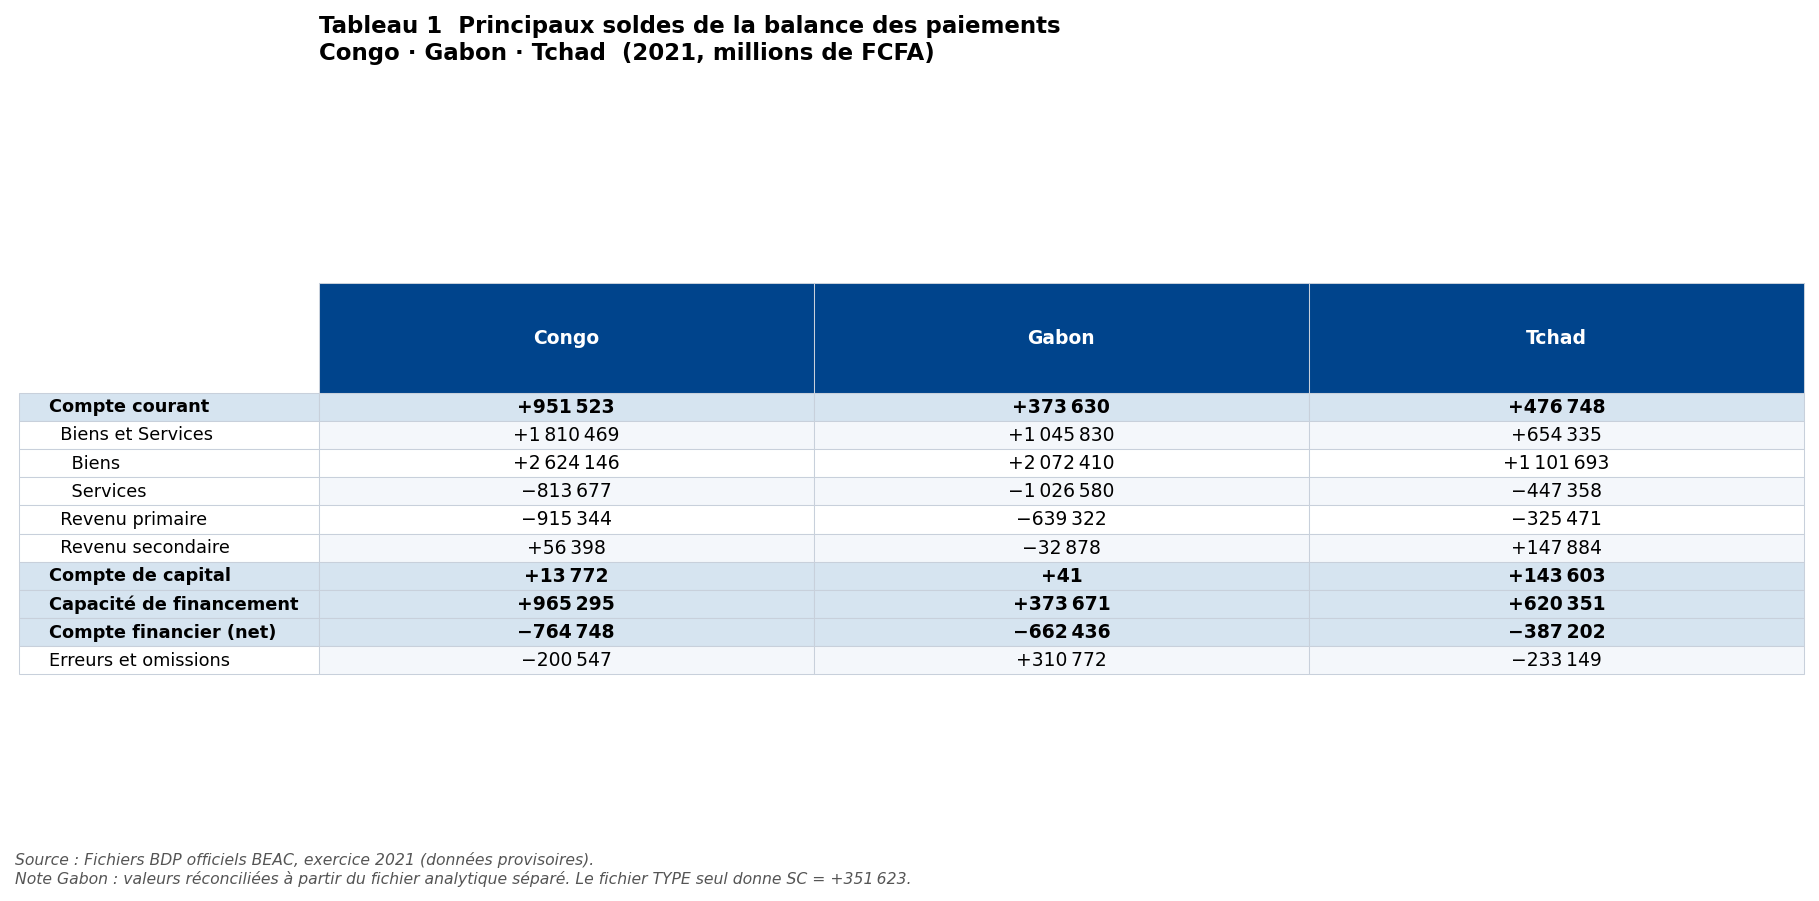

In [41]:
def _s(pays, cle):
    return fmt(bdp[pays][cle])

rows_t1 = [
    ('Compte courant',         'solde_courant'),
    ('  Biens et Services',    None),
    ('    Biens',              'biens'),
    ('    Services',           'services'),
    ('  Revenu primaire',      'rev_primaire'),
    ('  Revenu secondaire',    'rev_secondaire'),
    ('Compte de capital',      'compte_capital'),
    ('Capacité de financement','capacite_finan'),
    ('Compte financier (net)', 'compte_financier'),
    ('Erreurs et omissions',   'erreurs_omissions'),
]

data_t1 = {}
for p in PAYS:
    col = []
    for label, cle in rows_t1:
        if cle == 'biens_services':
            col.append(fmt(bdp[p]['biens'] + bdp[p]['services']))
        elif cle is None:
            # Biens et Services = Biens + Services
            col.append(fmt(bdp[p]['biens'] + bdp[p]['services']))
        else:
            col.append(fmt(bdp[p][cle]))
    data_t1[p] = col

df_t1 = pd.DataFrame(data_t1, index=[r[0] for r in rows_t1])

render_table(
    df_t1,
    title='Tableau 1  Principaux soldes de la balance des paiements\n'
          'Congo · Gabon · Tchad  (2021, millions de FCFA)',
    caption='Source : Fichiers BDP officiels BEAC, exercice 2021 (données provisoires).\n'
            'Note Gabon : valeurs réconciliées à partir du fichier analytique séparé.'
            ' Le fichier TYPE seul donne SC = +351\u202f623.',
    highlight_rows=[0, 6, 7, 8],
    filename=os.path.join(TABLEAUX, 'tab1_soldes_principaux.pdf'),
)

### Tableau 2  Indicateurs t de rétention des exportations

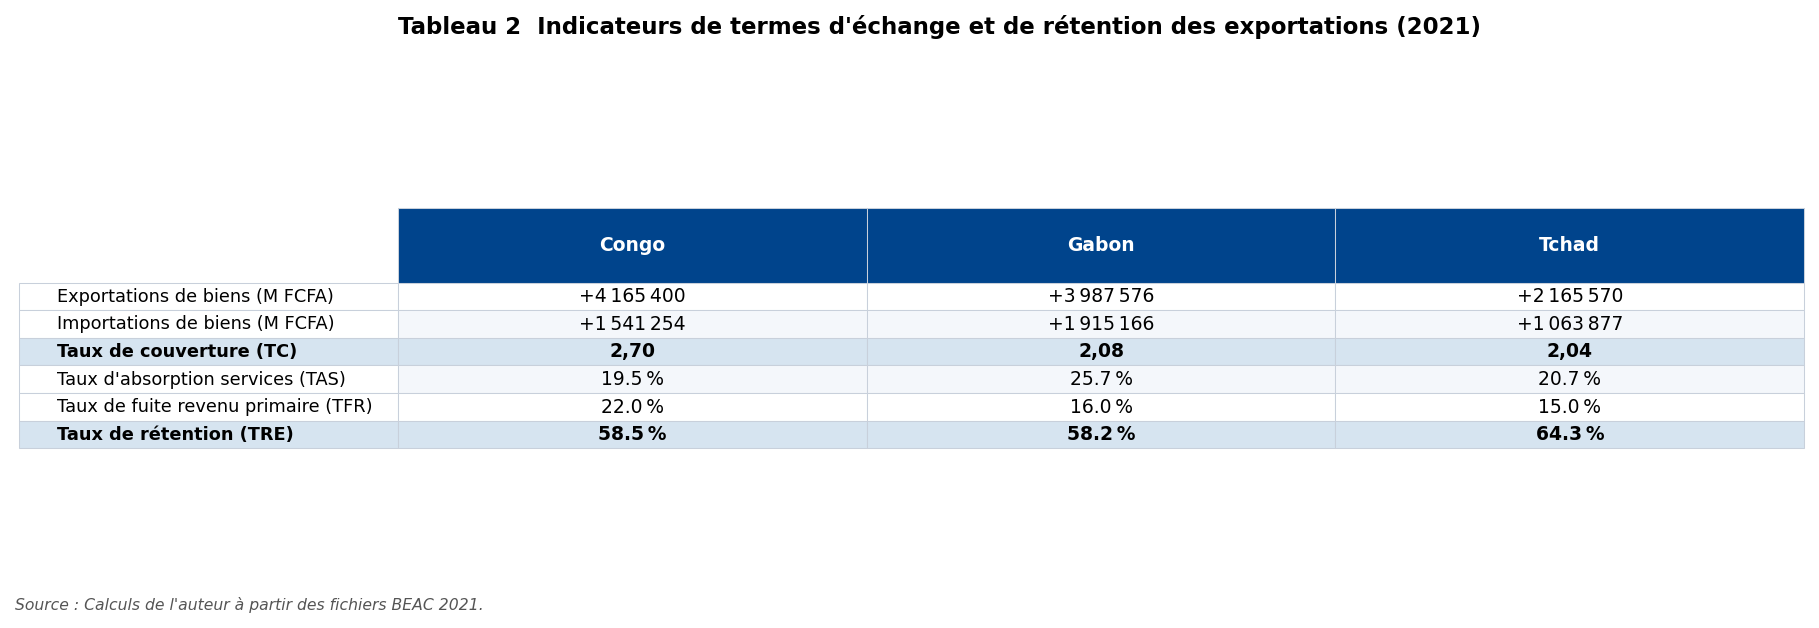

In [42]:
rows_t2 = [
    ('Exportations de biens (M FCFA)',        'exp_biens',  'mfcfa'),
    ('Importations de biens (M FCFA)',        'imp_biens',  'mfcfa'),
    ('Taux de couverture (TC)',               'tc',         'ratio'),
    ("Taux d'absorption services (TAS)",      'tas',        'pct_simple'),
    ('Taux de fuite revenu primaire (TFR)',   'tfr',        'pct_simple'),
    ('Taux de rétention (TRE)',               'tre',        'pct_simple'),
]

data_t2 = {}
for p in PAYS:
    col = []
    for _, cle, mode in rows_t2:
        v = indicateurs[p][cle]
        if mode == 'mfcfa':
            col.append(fmt(v, 'mfcfa'))
        elif mode == 'ratio':
            col.append(f"{v:.2f}".replace('.', ','))
        else:  # pct_simple (pas de signe +)
            col.append(f"{v:.1f}\u202f%")
    data_t2[p] = col

df_t2 = pd.DataFrame(data_t2, index=[r[0] for r in rows_t2])

render_table(
    df_t2,
    title="Tableau 2  Indicateurs t de rétention des exportations (2021)",
    caption="Source : Calculs de l'auteur à partir des fichiers BEAC 2021.",
    highlight_rows=[2, 5],
    filename=os.path.join(TABLEAUX, 'tab2_termes_echange.pdf'),
)

### Tableau 3  Tableau de bord comparatif (diagnostic macroéconomique)

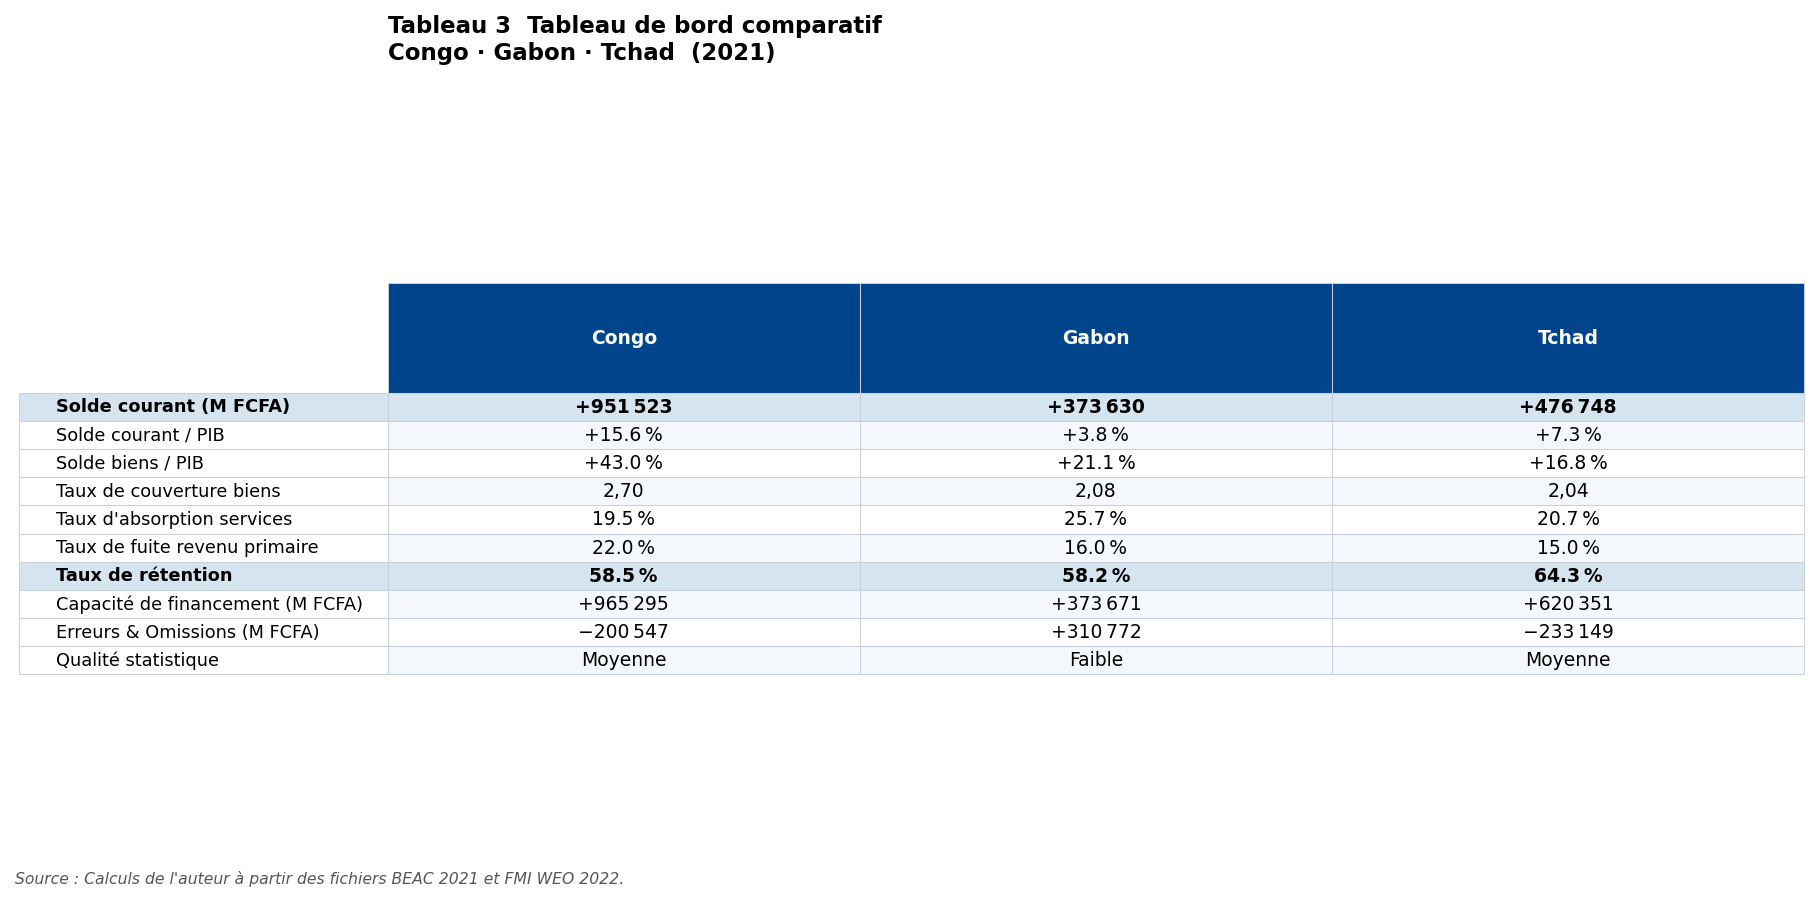

In [43]:
# Qualité statistique : évaluation basée sur le poids des erreurs/omissions
def qualite(pays):
    eo  = abs(bdp[pays]['erreurs_omissions'])
    sc  = abs(bdp[pays]['solde_courant'])
    ratio = eo / sc * 100 if sc else 0
    if ratio < 10:   return 'Bonne'
    if ratio < 60:   return 'Moyenne'
    return 'Faible'

rows_t3 = [
    'Solde courant (M FCFA)',
    'Solde courant / PIB',
    'Solde biens / PIB',
    'Taux de couverture biens',
    "Taux d'absorption services",
    'Taux de fuite revenu primaire',
    'Taux de rétention',
    'Capacité de financement (M FCFA)',
    'Erreurs & Omissions (M FCFA)',
    'Qualité statistique',
]

data_t3 = {}
for p in PAYS:
    ind = indicateurs[p]
    data_t3[p] = [
        fmt(bdp[p]['solde_courant']),
        fmt(ind['ratio_pib'], 'pct'),
        fmt(ind['ratio_biens_pib'], 'pct'),
        f"{ind['tc']:.2f}".replace('.', ','),
        f"{ind['tas']:.1f}\u202f%",
        f"{ind['tfr']:.1f}\u202f%",
        f"{ind['tre']:.1f}\u202f%",
        fmt(bdp[p]['capacite_finan']),
        fmt(bdp[p]['erreurs_omissions']),
        qualite(p),
    ]

df_t3 = pd.DataFrame(data_t3, index=rows_t3)

render_table(
    df_t3,
    title='Tableau 3  Tableau de bord comparatif\nCongo · Gabon · Tchad  (2021)',
    caption="Source : Calculs de l'auteur à partir des fichiers BEAC 2021 et FMI WEO 2022.",
    highlight_rows=[0, 6],
    filename=os.path.join(TABLEAUX, 'tab3_diagnostic.pdf'),
)

---
## 3. Graphiques

### Figure 1  Principaux soldes de la BDP

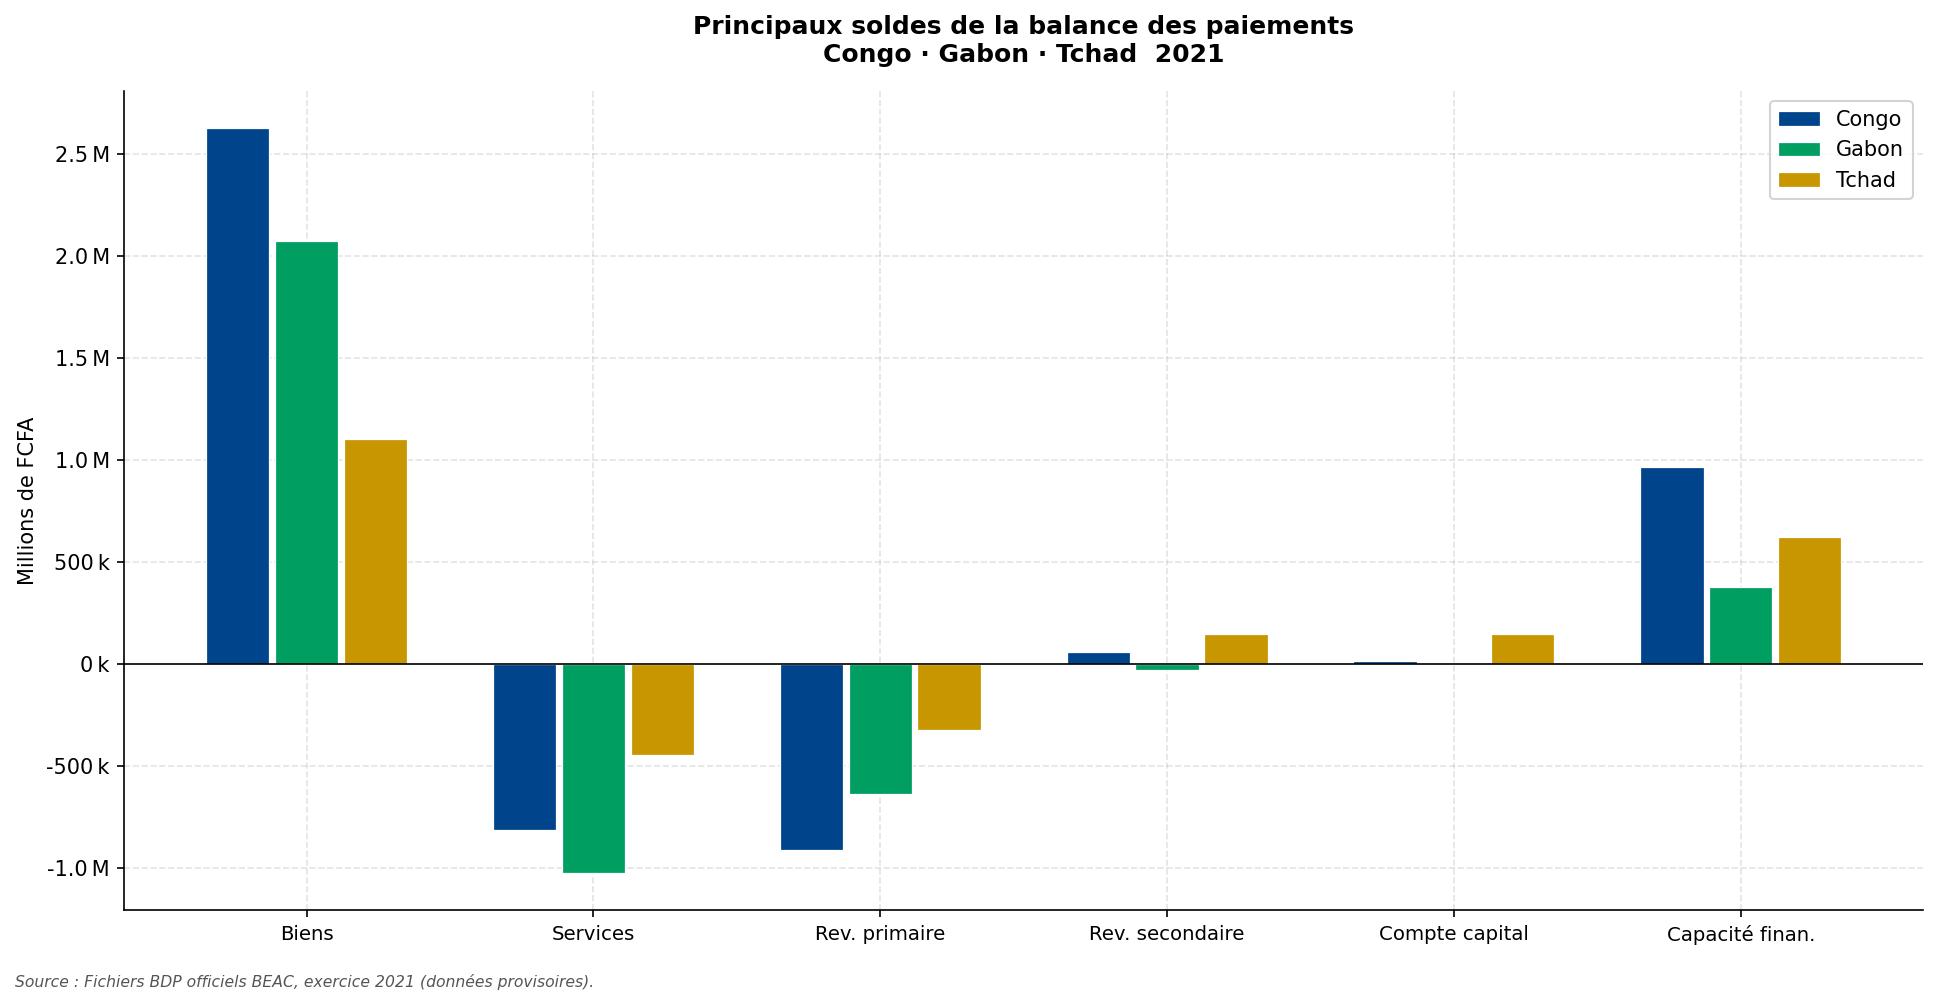

In [44]:
postes_fig1 = [
    ('Biens',              'biens'),
    ('Services',           'services'),
    ('Rev. primaire',      'rev_primaire'),
    ('Rev. secondaire',    'rev_secondaire'),
    ('Compte capital',     'compte_capital'),
    ('Capacité finan.',    'capacite_finan'),
]

labels_f1 = [p[0] for p in postes_fig1]
x  = np.arange(len(labels_f1))
w  = 0.24

fig, ax = plt.subplots(figsize=(13, 6.5))

for i, (pays, couleur) in enumerate(zip(PAYS, [CONGO, GABON, TCHAD])):
    vals = [bdp[pays][cle] for _, cle in postes_fig1]
    ax.bar(x + (i - 1) * w, vals, width=w * 0.92,
           color=couleur, edgecolor='white', linewidth=0.6,
           label=pays, zorder=3)

ax.axhline(0, color='black', linewidth=0.8, zorder=4)
ax.set_xticks(x)
ax.set_xticklabels(labels_f1, fontsize=9.5)
ax.set_ylabel('Millions de FCFA', fontsize=10)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(
    lambda v, _: f'{v/1e6:.1f}\u202fM' if abs(v) >= 1e6 else f'{v/1e3:.0f}\u202fk'))
ax.set_title('Principaux soldes de la balance des paiements\n'
             'Congo · Gabon · Tchad  2021',
             fontsize=12, fontweight='bold', pad=14)
ax.legend(fontsize=10, framealpha=0.85)
fig.text(0.01, -0.02,
         'Source : Fichiers BDP officiels BEAC, exercice 2021 (données provisoires).',
         fontsize=7.5, color='#555555', style='italic')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, 'fig1_soldes_principaux.pdf'), bbox_inches='tight')
plt.show()

### Figure 2  Décomposition des exportations : rétention vs. fuites

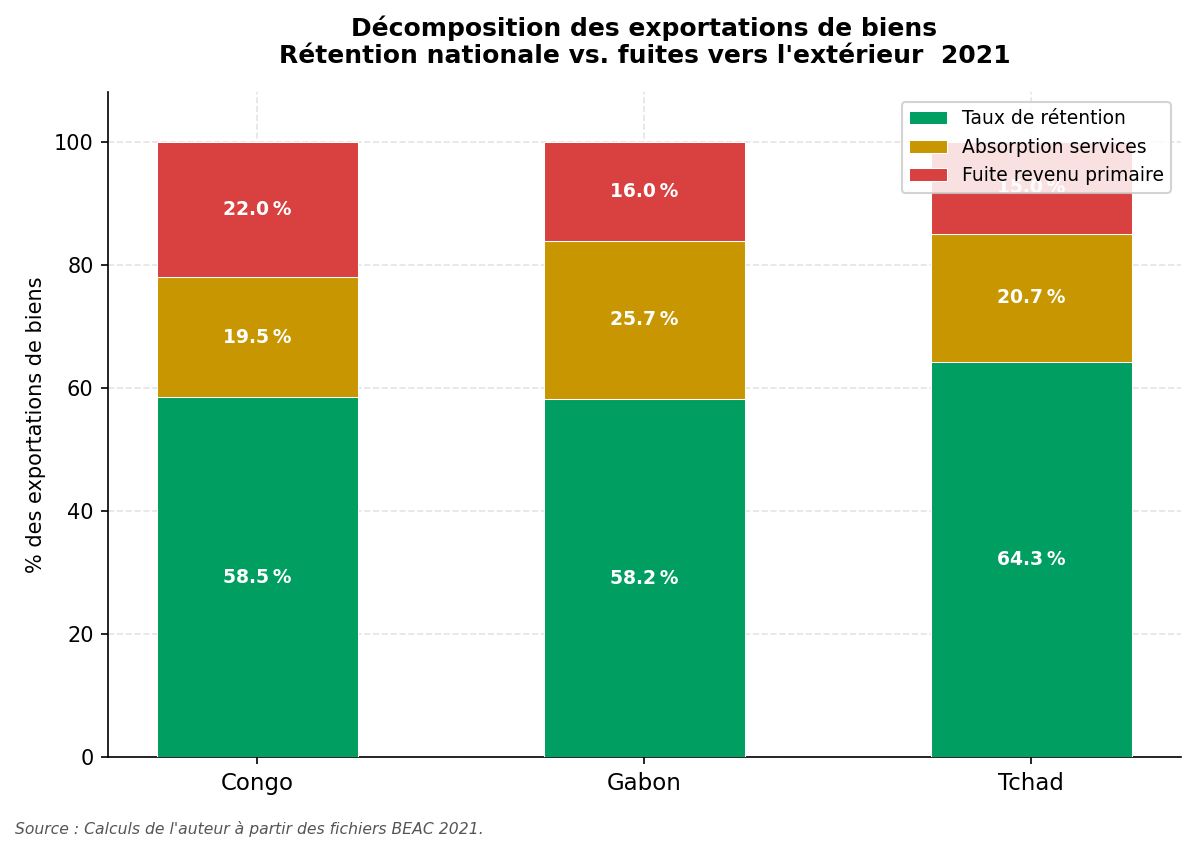

In [45]:
tre = [indicateurs[p]['tre'] for p in PAYS]
tas = [indicateurs[p]['tas'] for p in PAYS]
tfr = [indicateurs[p]['tfr'] for p in PAYS]
x   = np.arange(len(PAYS))

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.bar(x, tre, 0.52, label='Taux de rétention',
       color=GABON, edgecolor='white', linewidth=0.5, zorder=3)
ax.bar(x, tas, 0.52, bottom=tre,
       label='Absorption services',
       color=TCHAD, edgecolor='white', linewidth=0.5, zorder=3)
ax.bar(x, tfr, 0.52,
       bottom=[tre[i] + tas[i] for i in range(len(PAYS))],
       label='Fuite revenu primaire',
       color=RED1, edgecolor='white', linewidth=0.5, zorder=3)

for i, (t, s, f) in enumerate(zip(tre, tas, tfr)):
    ax.text(i, t / 2,         f'{t:.1f}\u202f%', ha='center', va='center',
            fontsize=9, fontweight='bold', color='white')
    ax.text(i, t + s / 2,     f'{s:.1f}\u202f%', ha='center', va='center',
            fontsize=9, fontweight='bold', color='white')
    ax.text(i, t + s + f / 2, f'{f:.1f}\u202f%', ha='center', va='center',
            fontsize=9, fontweight='bold', color='white')

ax.set_xticks(x); ax.set_xticklabels(PAYS, fontsize=11)
ax.set_ylabel('% des exportations de biens', fontsize=10)
ax.set_ylim(0, 108); ax.set_yticks(range(0, 101, 20))
ax.legend(fontsize=9, loc='upper right', framealpha=0.85)
ax.set_title("Décomposition des exportations de biens\n"
             "Rétention nationale vs. fuites vers l'extérieur  2021",
             fontsize=12, fontweight='bold', pad=14)
fig.text(0.01, -0.02,
         "Source : Calculs de l'auteur à partir des fichiers BEAC 2021.",
         fontsize=7.5, color='#555555', style='italic')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, 'fig2_retention_exportations.pdf'), bbox_inches='tight')
plt.show()

### Figure 3  Solde courant en % du PIB

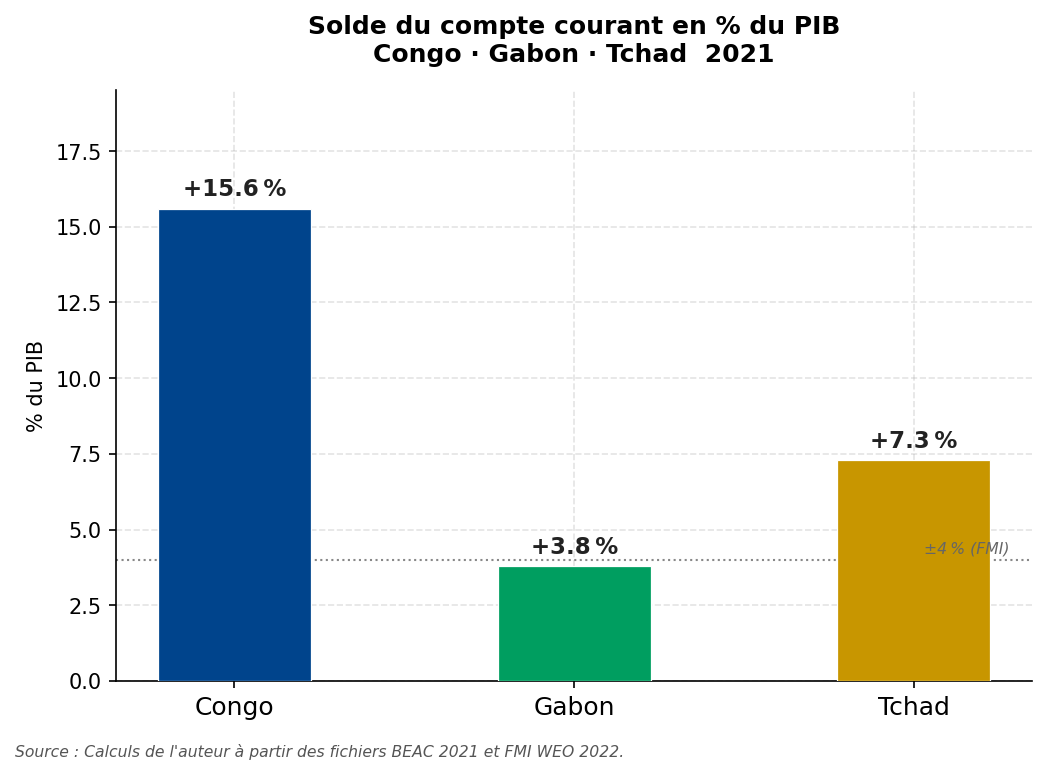

In [46]:
vals_pib = [indicateurs[p]['ratio_pib'] for p in PAYS]
x        = np.arange(len(PAYS))

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(x, vals_pib, 0.45,
              color=[CONGO, GABON, TCHAD],
              edgecolor='white', linewidth=0.6, zorder=3)

for bar, val in zip(bars, vals_pib):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.25,
            f'+{val:.1f}\u202f%',
            ha='center', va='bottom',
            fontsize=11, fontweight='bold', color='#222222')

ax.axhline(4, color='#888888', linewidth=1, linestyle=':', zorder=2)
ax.text(2.28, 4.22, '\u00b14\u202f% (FMI)',
        ha='right', fontsize=7.5, color='#666666', style='italic')
ax.set_xticks(x); ax.set_xticklabels(PAYS, fontsize=12)
ax.set_ylabel('% du PIB', fontsize=10)
ax.set_ylim(0, max(vals_pib) * 1.25)
ax.set_title('Solde du compte courant en % du PIB\nCongo · Gabon · Tchad  2021',
             fontsize=12, fontweight='bold', pad=14)
fig.text(0.01, -0.02,
         "Source : Calculs de l'auteur à partir des fichiers BEAC 2021 et FMI WEO 2022.",
         fontsize=7.5, color='#555555', style='italic')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, 'fig3_solde_pib.pdf'), bbox_inches='tight')
plt.show()

### Figure 4  Décomposition du compte courant par sous-poste

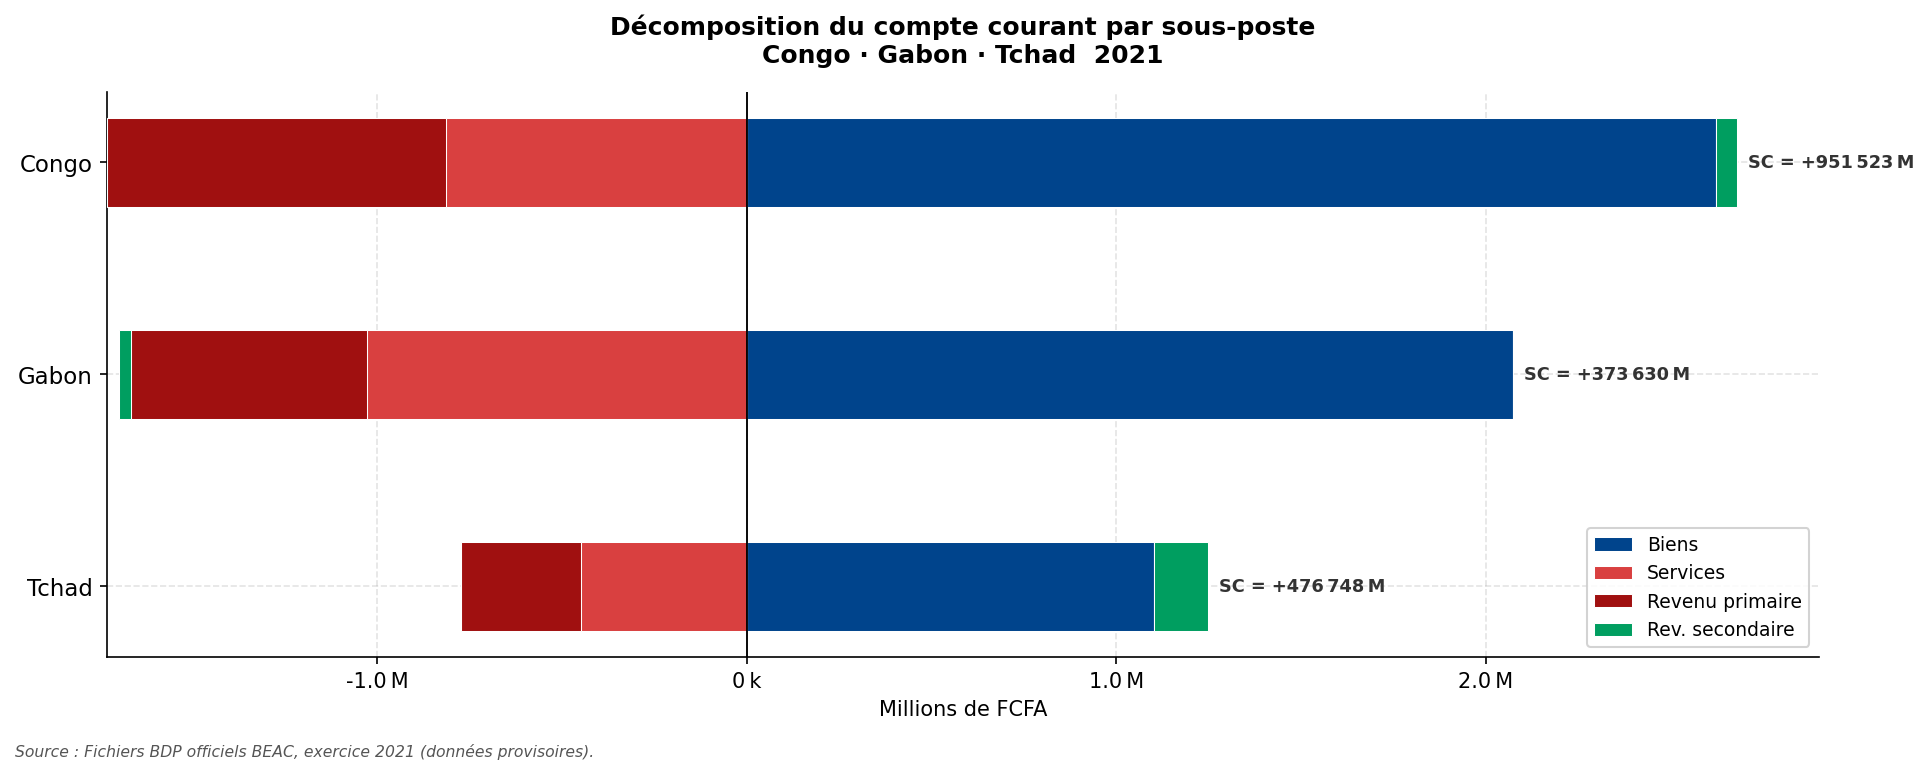

In [47]:
ordre     = ['Tchad', 'Gabon', 'Congo']
postes_cc = [
    ('Biens',           'biens',          CONGO),
    ('Services',        'services',       RED1),
    ('Revenu primaire', 'rev_primaire',   RED2),
    ('Rev. secondaire', 'rev_secondaire', GABON),
]
y        = np.arange(len(ordre))
left_pos = np.zeros(len(ordre))
left_neg = np.zeros(len(ordre))

fig, ax = plt.subplots(figsize=(13, 5))

for label, cle, couleur in postes_cc:
    vals = np.array([bdp[p][cle] for p in ordre], dtype=float)
    pos  = np.where(vals >= 0, vals, 0)
    neg  = np.where(vals <  0, vals, 0)
    ax.barh(y, pos, 0.42, left=left_pos,
            color=couleur, edgecolor='white', linewidth=0.5, label=label, zorder=3)
    ax.barh(y, neg, 0.42, left=left_neg,
            color=couleur, edgecolor='white', linewidth=0.5, zorder=3)
    left_pos += pos
    left_neg += neg

for i, p in enumerate(ordre):
    sc = bdp[p]['solde_courant']
    ax.text(left_pos[i] + 30_000, i,
            f'SC = +{int(sc):,}'.replace(',', '\u202f') + '\u202fM',
            va='center', fontsize=8.5, color='#333333', fontweight='bold')

ax.axvline(0, color='black', linewidth=0.9, zorder=4)
ax.set_yticks(y); ax.set_yticklabels(ordre, fontsize=11)
ax.set_xlabel('Millions de FCFA', fontsize=10)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda v, _: f'{v/1e6:.1f}\u202fM' if abs(v) >= 1e6 else f'{v/1e3:.0f}\u202fk'))
ax.legend(fontsize=9, loc='lower right', framealpha=0.85)
ax.set_title('Décomposition du compte courant par sous-poste\n'
             'Congo · Gabon · Tchad  2021',
             fontsize=12, fontweight='bold', pad=14)
fig.text(0.01, -0.02,
         'Source : Fichiers BDP officiels BEAC, exercice 2021 (données provisoires).',
         fontsize=7.5, color='#555555', style='italic')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, 'fig4_decomp_compte_courant.pdf'), bbox_inches='tight')
plt.show()